In [15]:
import pandas as pd
from sklearn.datasets import load_breast_cancer

# DATASET LOADING 
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)

# target variable 
y = pd.Series(data.target, name='target', index=X.index)

print("Feature Names (First 5):", data.feature_names[:5])
print("Target Mapping: 0 =", data.target_names[0], "| 1 =", data.target_names[1])
print("\nClass Counts:\n", y.value_counts().to_string())
print("\nDataset Shape:", X.shape)
display(X.head())

Feature Names (First 5): ['mean radius' 'mean texture' 'mean perimeter' 'mean area'
 'mean smoothness']
Target Mapping: 0 = malignant | 1 = benign

Class Counts:
 target
1    357
0    212

Dataset Shape: (569, 30)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


### Section 1: Dataset Loading
The Breast Cancer dataset is loaded with 569 samples and 30 features. Target labels are mapped as 0 for malignant (212 samples) and 1 for benign (357 samples). The target is converted to a Pandas Series to keep original row indices intact.

Missing Values Per Column:
 mean radius                0
mean texture               0
mean perimeter             0
mean area                  0
mean smoothness            0
mean compactness           0
mean concavity             0
mean concave points        0
mean symmetry              0
mean fractal dimension     0
radius error               0
texture error              0
perimeter error            0
area error                 0
smoothness error           0
compactness error          0
concavity error            0
concave points error       0
symmetry error             0
fractal dimension error    0
worst radius               0
worst texture              0
worst perimeter            0
worst area                 0
worst smoothness           0
worst compactness          0
worst concavity            0
worst concave points       0
worst symmetry             0
worst fractal dimension    0

Duplicate Full Rows: 0

Data Types Per Column:
 mean radius                float64
mean texture      

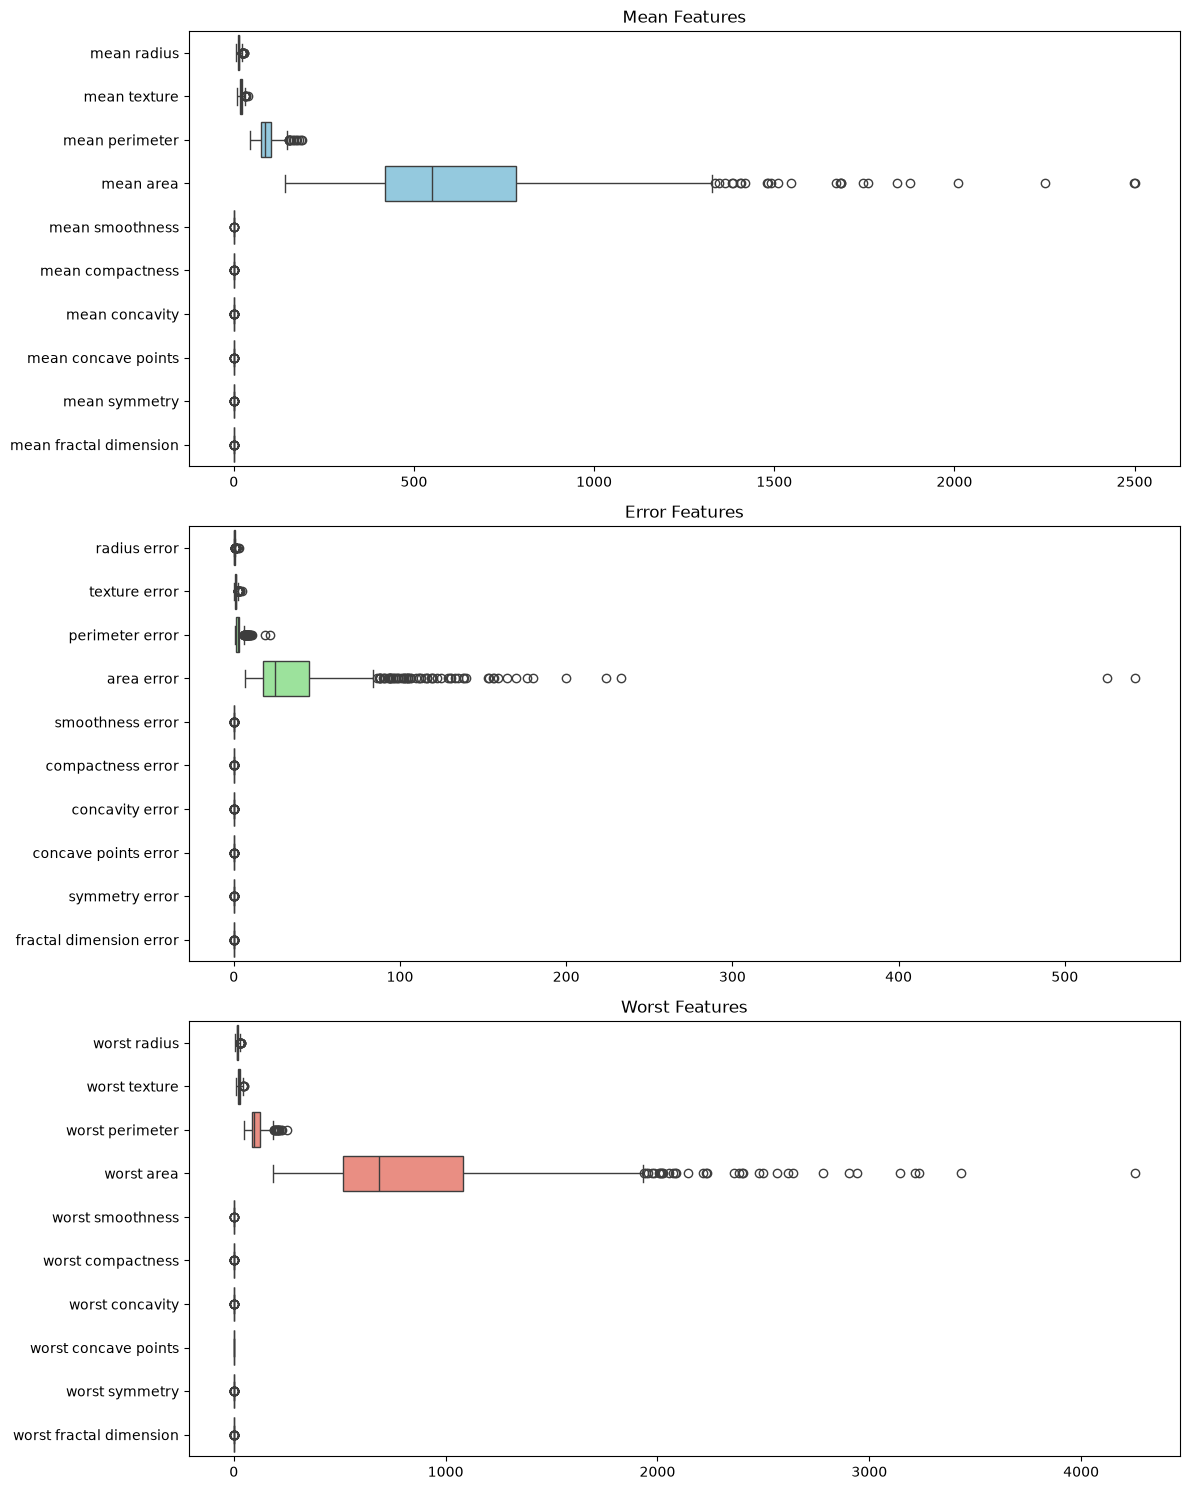

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

# DATA QUALITY CHECKS 
# Missing values per column
print("Missing Values Per Column:\n", X.isnull().sum().to_string())

# Check for full-row duplicates by temporarily combining X and y
full_df = X.copy()
full_df['target'] = y
print("\nDuplicate Full Rows:", full_df.duplicated().sum())

# Data types per column
print("\nData Types Per Column:\n", X.dtypes.to_string())

# group features for boxplots
features_mean = [col for col in X.columns if 'mean' in col]
features_error = [col for col in X.columns if 'error' in col]
features_worst = [col for col in X.columns if 'worst' in col]

fig, axes = plt.subplots(3, 1, figsize=(12, 15))
sns.boxplot(data=X[features_mean], orient="h", ax=axes[0], color="skyblue").set_title("Mean Features")
sns.boxplot(data=X[features_error], orient="h", ax=axes[1], color="lightgreen").set_title("Error Features")
sns.boxplot(data=X[features_worst], orient="h", ax=axes[2], color="salmon").set_title("Worst Features")
plt.tight_layout()
plt.show()

### Section 2: Data Quality Checks
Column-wise data quality checks confirm 0 missing values across all columns and 0 fully duplicated rows. The dataset consists of 30 numerical (float64) features and 0 categorical features. 

Boxplots indicate several extreme values, particularly in area-related features. In a medical context, these might represent natural variations in tumor cell measurements rather than simple data entry errors. Therefore, we have chosen to retain them for this initial modeling phase.

Descriptive Statistics:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500


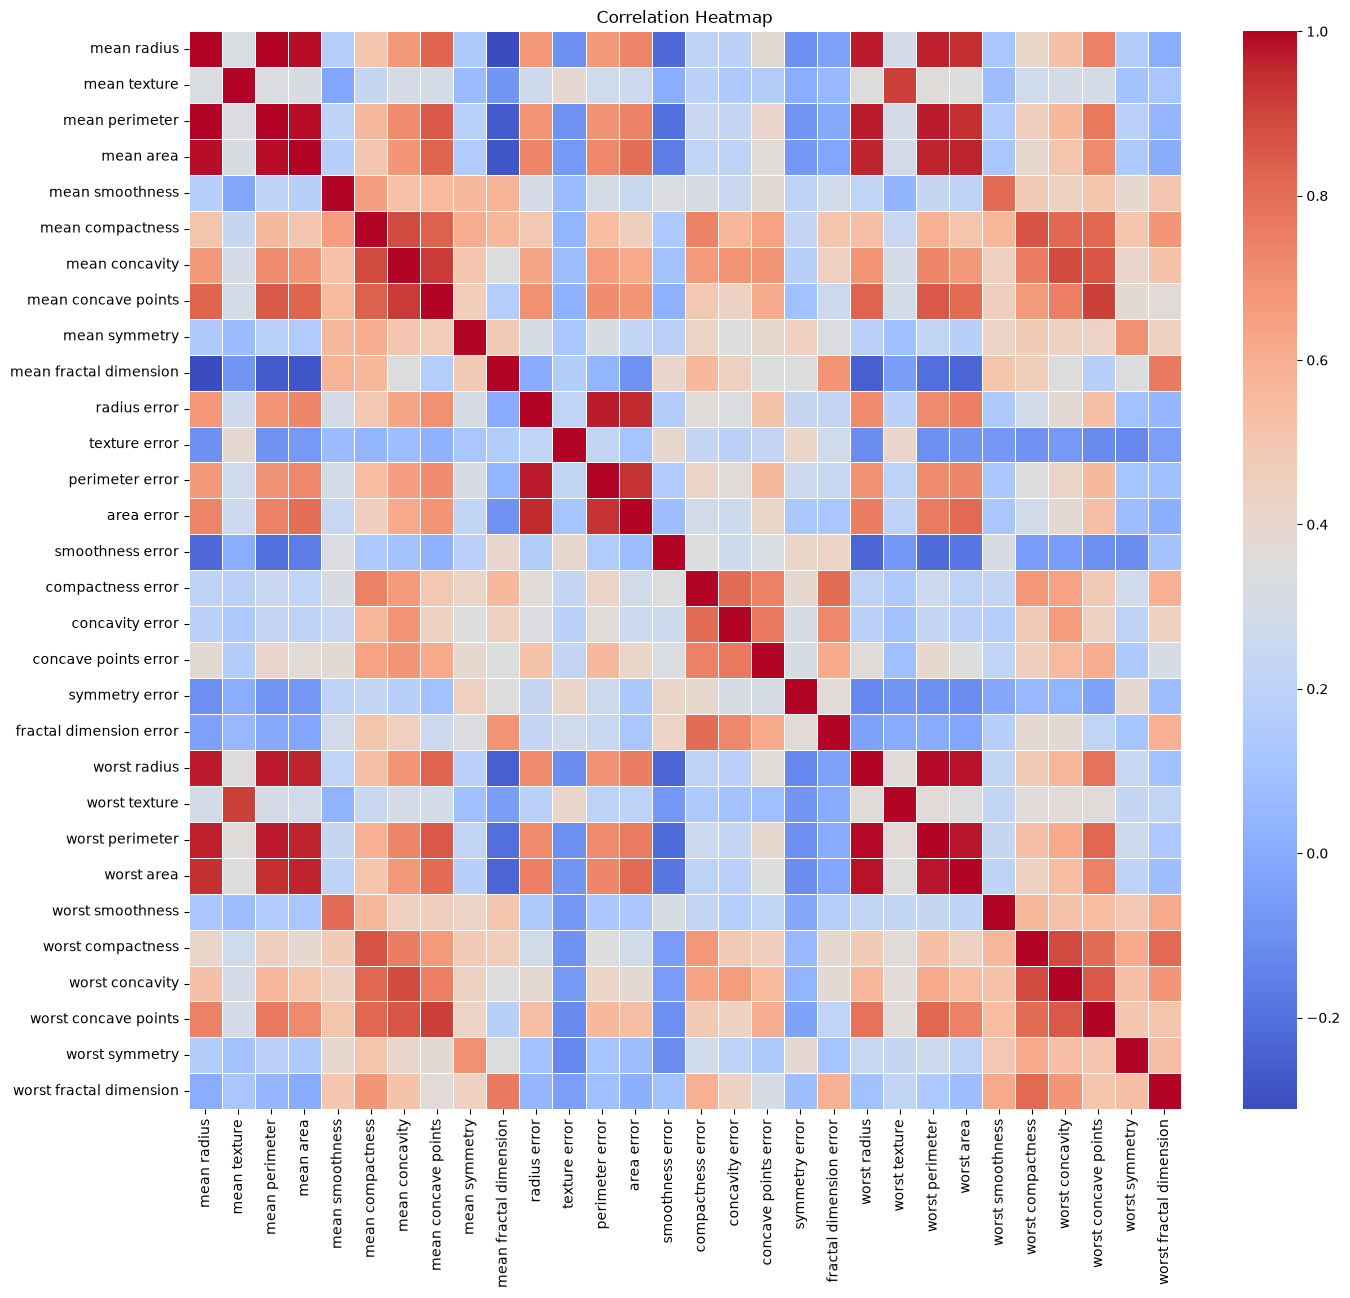

C:\Users\Abdullah\AppData\Local\Temp\ipykernel_28956\2834113582.py:18: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(['Malignant (0)', 'Benign (1)']) # Sınıf adları eklendi


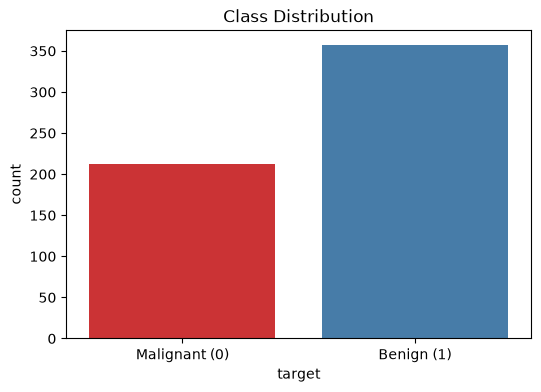

Top 3 Feature Pairs:
mean perimeter   mean radius     0.997855
worst perimeter  worst radius    0.993708
mean area        mean radius     0.987357
dtype: float64


In [ ]:
import numpy as np

# 3. EDA 
# summary stats
print("Descriptive Statistics:")
display(X.describe())

# heatmap
plt.figure(figsize=(16, 14))
corr_matrix = X.corr()
sns.heatmap(corr_matrix, annot=False, cmap="coolwarm", linewidths=0.5)
plt.title("Correlation Heatmap")
plt.show()

# class distribution
plt.figure(figsize=(6, 4))
ax = sns.countplot(x=y, palette="Set1", hue=y, legend=False)
ax.set_xticklabels(['Malignant (0)', 'Benign (1)']) # Sınıf adları eklendi
plt.title("Class Distribution")
plt.show()

# find top 3 feature correlations
corr_abs = corr_matrix.abs()
upper_tri = corr_abs.where(np.triu(np.ones(corr_abs.shape), k=1).astype(bool))
top_3 = upper_tri.unstack().sort_values(ascending=False).head(3)
print("Top 3 Feature Pairs:")
print(top_3)

### Section 3: Exploratory Data Analysis
In the `describe()` table, the 25% row represents Q1, 50% is the median, and 75% is Q3. 

Key observations:
1. Features have vastly different scales (e.g., area vs. smoothness), suggesting that feature scaling is likely to matter for distance-based models.
2. The heatmap shows a highly correlated block among size metrics (`radius`, `perimeter`, and `area`), which aligns with the top 3 feature pairs extracted computationally.

In [ ]:
from sklearn.model_selection import train_test_split

# 4. DATA SPLITTING 
# fix 20% test set
X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=42)

X_train_dict, X_val_dict, y_train_dict, y_val_dict = {}, {}, {}, {}
SEEDS = [42, 52, 62]
split_summary = []

# split remaining 80% to train and val
for seed in SEEDS:
    X_train, X_val, y_train, y_val = train_test_split(
        X_temp, y_temp, test_size=0.125, stratify=y_temp, random_state=seed
    )
    X_train_dict[seed], X_val_dict[seed] = X_train, X_val
    y_train_dict[seed], y_val_dict[seed] = y_train, y_val
    
    # check data leakage and totals per seed
    train_idx, val_idx, test_idx = set(y_train.index), set(y_val.index), set(y_test.index)
    overlap = len(train_idx & val_idx) + len(train_idx & test_idx) + len(val_idx & test_idx)
    total_rows = len(train_idx) + len(val_idx) + len(test_idx)
    
    for subset_name, y_subset in [("Train", y_train), ("Val", y_val), ("Test", y_test)]:
        split_summary.append({
            "Seed": seed, 
            "Subset": subset_name, 
            "Total": len(y_subset),
            "Ratio": f"{len(y_subset)/569 * 100:.1f}%",
            "Class 0": y_subset.value_counts().get(0, 0), 
            "Class 1": y_subset.value_counts().get(1, 0),
            "Overlap": overlap,
            "Sum=569": total_rows == 569
        })

display(pd.DataFrame(split_summary))

,Seed,Subset,Total,Ratio,Class 0,Class 1,Overlap,Sum=569
0,42,Train,398,69.9%,149,249,0,True
1,42,Val,57,10.0%,21,36,0,True
2,42,Test,114,20.0%,42,72,0,True
3,52,Train,398,69.9%,149,249,0,True
4,52,Val,57,10.0%,21,36,0,True
5,52,Test,114,20.0%,42,72,0,True
6,62,Train,398,69.9%,149,249,0,True
7,62,Val,57,10.0%,21,36,0,True
8,62,Test,114,20.0%,42,72,0,True


### Section 4: Splitting the Datasets
The dataset is split into training (~70%), validation (~10%), and a fixed test set (20%). Stratification preserves the target distribution. The summary table and index checks confirm that test indices remain constant, the total sums to 569, and there is zero overlap between subsets (no data leakage). Original row indices are preserved and inspectable.

In [20]:
from sklearn.preprocessing import StandardScaler

#  5. DATA PREPROCESSING (FEATURE SCALING) 
# Dictionaries to store scaled versions for each seed
X_train_scaled_dict = {}
X_val_scaled_dict = {}
scalers_dict = {} 

for seed in SEEDS:
    scaler = StandardScaler()
    
    # CRITICAL: Fit ONLY on training data to prevent data leakage!
    X_train_scaled_dict[seed] = scaler.fit_transform(X_train_dict[seed])
    
    # Transform validation data using the parameters learned from train
    X_val_scaled_dict[seed] = scaler.transform(X_val_dict[seed])
    
    scalers_dict[seed] = scaler

print("Scaling completed without data leakage. Example scaled data (Train, Seed 42):")
display(pd.DataFrame(X_train_scaled_dict[42], columns=X.columns).head(3))

Scaling completed without data leakage. Example scaled data (Train, Seed 42):


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,-0.464835,0.176821,-0.467521,-0.518737,-0.883771,-0.073305,-0.280632,-0.466742,-0.076775,-0.069315,...,-0.573411,-0.379056,-0.561075,-0.578285,-1.226438,-0.259443,-0.416465,-0.584935,-0.339632,-0.358158
1,-1.084133,-1.553003,-1.065325,-0.944480,0.250510,-0.553959,-0.868776,-0.752546,-0.009649,0.375173,...,-1.001136,-1.547363,-1.000394,-0.854885,0.069897,-0.573037,-0.892843,-0.723620,0.046080,-0.381146
2,-0.715369,-0.014881,-0.721221,-0.693926,-0.814026,-0.520657,-0.441841,-0.889004,0.806456,-0.044313,...,-0.653609,0.236588,-0.611199,-0.632617,-0.345992,-0.395869,-0.116701,-0.728397,0.196078,-0.073535


### Section 5: Feature Scaling
To prevent data leakage, `StandardScaler` was exclusively fitted to the training set of each respective seed. The learned parameters (mean and standard deviation) were then applied to transform both the training and corresponding validation subsets. The fixed test set remains entirely isolated and unscaled at this stage.